# 1.1 ResNet-50 features: GRAZPEDWRI-DX

`data/processed/` → frozen ResNet-50 features → Logistic Regression / Gradient Boosting → test predictions and figures

Uses Fahim's `0.1_data-pipeline_fahim.ipynb` outputs. ResNet-50 weights are frozen; only the two classifiers are trained.

| Output | Contents |
|---|---|
| `features/resnet50_features.npy` | One 2048-value feature vector per X-ray, same row order as `graz.csv` |
| `models/resnet50_baseline_predictions.csv` | Test labels, clean/cast flags and probabilities from both models and seeds |
| `reports/figures/resnet50_baseline_auc.png` | Full vs clean test ROC-AUC comparison |

The processed images and feature cache are stored in Google Drive. The notebook needs `graz.csv` and `graz_256x512_u8.npy` from the 0.1 pipeline.

## 1. Load data

Load the processed images and labels from Google Drive. `graz.csv` has the train/validation/test split by patient, and its rows match the image array.

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

import torch
import numpy as np
import pandas as pd
from pathlib import Path

processed = Path("/content/drive/MyDrive/wrist-fracture-detection/processed")

X = np.load(processed / "graz_256x512_u8.npy", mmap_mode="r")
df = pd.read_csv(processed / "graz.csv")

print("GPU available:", torch.cuda.is_available())
print("Images:", X.shape)
print("Metadata:", df.shape)

Mounted at /content/drive
GPU available: True
Images: (20327, 512, 256)
Metadata: (20327, 13)


## 2. Load ResNet-50

Use ImageNet-pretrained ResNet-50 with its final classification layer removed. Freeze the weights so it produces 2048 features per X-ray without training the CNN.

In [ ]:
import torch
import torch.nn as nn
from torchvision import models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load ResNet-50 pretrained on ImageNet
weights = models.ResNet50_Weights.DEFAULT
resnet = models.resnet50(weights=weights)

# Remove the final classification layer
resnet.fc = nn.Identity()

# Freeze all model parameters
for param in resnet.parameters():
    param.requires_grad = False

resnet = resnet.to(device)
resnet.eval()

print("Device:", device)
print("ResNet-50 ready!")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 184MB/s]


Device: cuda
ResNet-50 ready!


Check one image before extracting all features. Convert grayscale to three channels, resize to 224×224 and normalize with ImageNet values.

In [ ]:
import torch.nn.functional as F

# Select the first wrist X-ray
image = torch.tensor(X[0].copy(), dtype=torch.float32)


image = image.unsqueeze(0).repeat(3, 1, 1) / 255.0


image = F.interpolate(
    image.unsqueeze(0),
    size=(224, 224),
    mode="bilinear",
    align_corners=False
)

# Normalize using ImageNet values
mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

image = ((image - mean) / std).to(device)

# Extract features
with torch.no_grad():
    features = resnet(image)

print("Input shape:", image.shape)
print("Feature shape:", features.shape)

Input shape: torch.Size([1, 3, 224, 224])
Feature shape: torch.Size([1, 2048])


## 3. Extract and save features



In [ ]:
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm
import numpy as np

class WristDataset(Dataset):
    def __init__(self, images):
        self.images = images

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):

        image = torch.from_numpy(
            np.array(self.images[idx], copy=True)
        ).float()


        image = image.unsqueeze(0).repeat(3, 1, 1) / 255.0


        image = F.interpolate(
            image.unsqueeze(0),
            size=(224, 224),
            mode="bilinear",
            align_corners=False
        ).squeeze(0)


        mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
        std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

        return (image - mean) / std


dataset = WristDataset(X)

loader = DataLoader(
    dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

# Cache location (outside GitHub)
feature_dir = Path("/content/drive/MyDrive/wrist-fracture-detection/features")
feature_dir.mkdir(parents=True, exist_ok=True)
feature_path = feature_dir / "resnet50_features.npy"

if feature_path.exists():
    print("Loading cached features:", feature_path)
    features_array = np.load(feature_path)
else:
    # Extract one 2,048-dimensional feature vector per image
    all_features = []
    resnet.eval()
    with torch.inference_mode():
        for images in tqdm(loader, desc="Extracting ResNet-50 features"):
            images = images.to(device)
            features = resnet(images)
            all_features.append(features.cpu().numpy())
    features_array = np.concatenate(all_features, axis=0)
    np.save(feature_path, features_array)
    print("Saved features:", feature_path)

assert features_array.shape == (len(df), 2048), "Features and labels must align"
print("Extracted features shape:", features_array.shape)


Extracting ResNet-50 features:   0%|          | 0/636 [00:00<?, ?it/s]

Extracted features shape: (20327, 2048)


Check that the feature cache exists and has the expected shape and size.

In [ ]:
# Verify the cached feature file
print("Features saved:", feature_path.exists())
print("Feature shape:", features_array.shape)
print("File size:", round(feature_path.stat().st_size / 1e6, 2), "MB")


Features saved: True
Feature shape: (20327, 2048)
File size: 166.52 MB


## 4. Logistic Regression

Use the training split to fit a StandardScaler and Logistic Regression. Run seeds 1337 and 3407 and calculate ROC-AUC on the validation split.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score
import numpy as np

# Step 5: Train Logistic Regression


train_mask = (df["split"] == "train").to_numpy()
val_mask = (df["split"] == "val").to_numpy()

# Get features
X_train = features_array[train_mask]
X_val = features_array[val_mask]

# Get fracture labels (0 = no fracture, 1 = fracture)
y_train = df.loc[train_mask, "label"].to_numpy()
y_val = df.loc[val_mask, "label"].to_numpy()


lr_models = {}
lr_results = []


for seed in [1337, 3407]:

    print(f"\nTraining Logistic Regression with seed {seed}...")

    model = make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=2000,
            random_state=seed
        )
    )

    # Train on training data only
    model.fit(X_train, y_train)

    # Predict probabilities on validation data
    val_probs = model.predict_proba(X_val)[:, 1]

    # Calculate ROC-AUC
    val_auc = roc_auc_score(y_val, val_probs)

    lr_models[seed] = model

    lr_results.append({
        "Model": "Logistic Regression",
        "Seed": seed,
        "Validation ROC-AUC": val_auc
    })

    print(f"Validation ROC-AUC: {val_auc:.4f}")




Training Logistic Regression with seed 1337...
Validation ROC-AUC: 0.8817

Training Logistic Regression with seed 3407...
Validation ROC-AUC: 0.8817

Logistic Regression completed!


## 5. Gradient Boosting

Train Histogram Gradient Boosting on the same frozen features and training split. Run seeds 1337 and 3407 and calculate validation ROC-AUC.

In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score
import pandas as pd

# Step 7: Train Gradient Boosting

gb_models = {}
gb_results = []

for seed in [1337, 3407]:

    print(f"\nTraining Gradient Boosting with seed {seed}...")

    model = HistGradientBoostingClassifier(
        max_iter=100,
        learning_rate=0.1,
        max_leaf_nodes=31,
        random_state=seed
    )

    # Train using ResNet-50 features
    model.fit(X_train, y_train)

    # Predict probabilities on validation data
    val_probs = model.predict_proba(X_val)[:, 1]

    # Calculate ROC-AUC
    val_auc = roc_auc_score(y_val, val_probs)

    gb_models[seed] = model

    gb_results.append({
        "Model": "Gradient Boosting",
        "Seed": seed,
        "Validation ROC-AUC": val_auc
    })

    print(f"Validation ROC-AUC: {val_auc:.4f}")




Training Gradient Boosting with seed 1337...
Validation ROC-AUC: 0.8919

Training Gradient Boosting with seed 3407...
Validation ROC-AUC: 0.8883

Gradient Boosting completed!


## 6. Clean test subset

- `clean`: first visit and no cast, defined in the 0.1 pipeline.
- Check that clean test images have no casts or follow-up exams.

In [ ]:
# Check the clean test subset
clean_test = df[
    (df["split"] == "test") &
    (df["clean"] == 1)
]

print("Clean test images:", len(clean_test))
print("Images with casts:", clean_test["cast"].sum())
print("Follow-up images:", clean_test["follow_up"].sum())
print("Fracture rate:", round(clean_test["label"].mean(), 4))

Clean test images: 1637
Images with casts: 0
Follow-up images: 0
Fracture rate: 0.3971


## 7. Test evaluation

Report ROC-AUC on the full test set and the clean test subset for both models and both seeds. No test images are used for training.

- Full test: 2943 images.
- Clean test: 1637 images.

In [ ]:
from sklearn.metrics import roc_auc_score
import pandas as pd
import numpy as np

# Identify test images
test_mask = (df["split"] == "test").to_numpy()

# Identify clean test images
clean_test_mask = (
    (df["split"] == "test") &
    (df["clean"] == 1)
).to_numpy()

# Prepare test data
X_test = features_array[test_mask]
y_test = df.loc[test_mask, "label"].to_numpy()

X_clean_test = features_array[clean_test_mask]
y_clean_test = df.loc[clean_test_mask, "label"].to_numpy()

print("Full test images:", len(X_test))
print("Clean test images:", len(X_clean_test))

# Evaluate both models and both seeds
test_results = []

for model_name, models_dict in [
    ("Logistic Regression", lr_models),
    ("Gradient Boosting", gb_models)
]:
    for seed, model in models_dict.items():

        # Predict fracture probabilities
        full_probs = model.predict_proba(X_test)[:, 1]
        clean_probs = model.predict_proba(X_clean_test)[:, 1]


        full_auc = roc_auc_score(y_test, full_probs)
        clean_auc = roc_auc_score(y_clean_test, clean_probs)

        test_results.append({
            "Model": model_name,
            "Seed": seed,
            "Full Test AUC": full_auc,
            "Clean Test AUC": clean_auc
        })


test_results_df = pd.DataFrame(test_results)
display(test_results_df.round(4))

Full test images: 2943
Clean test images: 1637


,Model,Seed,Full Test AUC,Clean Test AUC
0,Logistic Regression,1337,0.8888,0.8199
1,Logistic Regression,3407,0.8888,0.8199
2,Gradient Boosting,1337,0.9072,0.8327
3,Gradient Boosting,3407,0.9078,0.8358


### Results

| Model | Seed | Full test AUC | Clean test AUC |
|---|---:|---:|---:|
| Logistic Regression | 1337 | 0.8888 | 0.8199 |
| Logistic Regression | 3407 | 0.8888 | 0.8199 |
| Gradient Boosting | 1337 | 0.9072 | 0.8327 |
| Gradient Boosting | 3407 | 0.9078 | 0.8358 |

Gradient Boosting had the highest AUC. All four runs scored lower on the clean subset. This is worth checking for shortcut learning, but the difference alone does not show that the models use casts. The clean subset also has a different fracture rate than the full test set.

## 8. Save predictions

Save the test labels, patient and image IDs, clean/cast flags, and fracture probabilities for both classifiers and seeds.

Output: `models/resnet50_baseline_predictions.csv` (2943 rows).

In [ ]:
from pathlib import Path
import pandas as pd

# Save to Drive first so results survive a Colab reset
project_dir = Path("/content/drive/MyDrive/wrist-fracture-detection")
models_dir = project_dir / "models"
models_dir.mkdir(parents=True, exist_ok=True)


predictions_df = df.loc[
    df["split"] == "test",
    ["filestem", "patient_id", "label", "cast", "clean", "split"]
].copy().reset_index(drop=True)


for name, model_dict in [
    ("logistic_regression", lr_models),
    ("gradient_boosting", gb_models)
]:
    for seed, model in model_dict.items():
        predictions_df[f"{name}_seed{seed}"] = (
            model.predict_proba(X_test)[:, 1]
        )

predictions_path = models_dir / "resnet50_baseline_predictions.csv"
predictions_df.to_csv(predictions_path, index=False)

print("Predictions saved:", predictions_path)
print("Number of rows:", len(predictions_df))
display(predictions_df.head())

Predictions saved: /content/drive/MyDrive/wrist-fracture-detection/models/resnet50_baseline_predictions.csv
Number of rows: 2943


,filestem,patient_id,label,cast,clean,split,logistic_regression_seed1337,logistic_regression_seed3407,gradient_boosting_seed1337,gradient_boosting_seed3407
0,0006_0290481819_01_WRI-R2_M011,6,1,0,1,test,0.970622,0.970622,0.710917,0.736028
1,0006_0290481856_01_WRI-R1_M011,6,1,0,1,test,0.718060,0.718060,0.676102,0.756916
2,0008_1128992395_01_WRI-L1_M005,8,1,0,1,test,0.908838,0.908838,0.728381,0.918264
3,0008_1128992441_01_WRI-L2_M005,8,1,0,1,test,0.074357,0.074357,0.447829,0.526374
4,0023_0657841969_01_WRI-L1_M012,23,0,0,1,test,0.790165,0.790165,0.521307,0.527477


## 9. Plot results

Compare full and clean test ROC-AUC for both models and seeds.

Output: `reports/figures/resnet50_baseline_auc.png`.

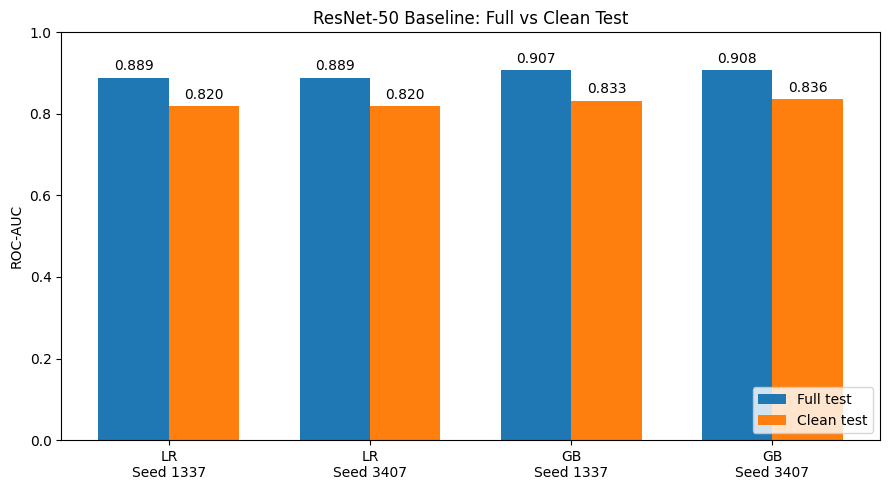

Figure saved: /content/drive/MyDrive/wrist-fracture-detection/reports/figures/resnet50_baseline_auc.png
File exists: True


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

# Create the figures folder
figures_dir = Path(
    "/content/drive/MyDrive/wrist-fracture-detection/reports/figures"
)
figures_dir.mkdir(parents=True, exist_ok=True)


plot_df = test_results_df.copy()

labels = [
    ("LR" if model == "Logistic Regression" else "GB") + f"\nSeed {seed}"
    for model, seed in zip(plot_df["Model"], plot_df["Seed"])
]

x = np.arange(len(labels))
width = 0.35

# Plot full vs clean test ROC-AUC
fig, ax = plt.subplots(figsize=(9, 5))

bars_full = ax.bar(
    x - width / 2,
    plot_df["Full Test AUC"],
    width,
    label="Full test"
)

bars_clean = ax.bar(
    x + width / 2,
    plot_df["Clean Test AUC"],
    width,
    label="Clean test"
)

ax.set_ylabel("ROC-AUC")
ax.set_title("ResNet-50 Baseline: Full vs Clean Test")
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylim(0, 1)
ax.legend(loc="lower right")

ax.bar_label(bars_full, fmt="%.3f", padding=3)
ax.bar_label(bars_clean, fmt="%.3f", padding=3)

fig.tight_layout()


figure_path = figures_dir / "resnet50_baseline_auc.png"
fig.savefig(figure_path, dpi=200, bbox_inches="tight")

plt.show()

print("Figure saved:", figure_path)
print("File exists:", figure_path.exists())

## 10. Checks

Check that the feature cache, prediction CSV and figure were saved to Google Drive.

In [ ]:
from pathlib import Path

project = Path("/content/drive/MyDrive/wrist-fracture-detection")

files = [
    "features/resnet50_features.npy",
    "models/resnet50_baseline_predictions.csv",
    "reports/figures/resnet50_baseline_auc.png"
]

for filename in files:
    path = project / filename
    print(filename, ":", path.exists())

features/resnet50_features.npy : True
models/resnet50_baseline_predictions.csv : True
reports/figures/resnet50_baseline_auc.png : True


## Files for the team

- Notebook: `notebooks/1.1_resnet50-features_zahra.ipynb`
- Predictions: `models/resnet50_baseline_predictions.csv`
- Figure: `reports/figures/resnet50_baseline_auc.png`

